<a href="https://colab.research.google.com/github/mafdhalrzy/ButterflyImageClassification/blob/main/ButterflyImageClassification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Library yang sering digunakan
import os, shutil
import zipfile
import random
from random import sample
import shutil
from shutil import copyfile
import pathlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm as tq

In [2]:
# Libraries untuk pemrosesan data gambar
import cv2
from PIL import Image
import skimage
from skimage import io
from skimage.transform import resize
from skimage.transform import rotate, AffineTransform, warp
from skimage import img_as_ubyte
from skimage.exposure import adjust_gamma
from skimage.util import random_noise

In [3]:
# Libraries untuk pembangunan model
import keras
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import tensorflow as tf
from tensorflow.keras import Model, layers, Input
from tensorflow.keras.preprocessing import image
from tensorflow.keras.preprocessing.image import ImageDataGenerator, img_to_array, load_img
from tensorflow.keras.optimizers import Adam, RMSprop, SGD
from tensorflow.keras.layers import InputLayer, Conv2D, SeparableConv2D, MaxPooling2D, MaxPool2D, Dense, Flatten, Dropout, BatchNormalization, GlobalAveragePooling2D
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.densenet import DenseNet121
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import ModelCheckpoint, Callback, EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.losses import CategoricalCrossentropy
from tensorflow.keras.regularizers import l2

In [4]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [5]:
# Mencetak versi TensorFlow yang sedang digunakan
print(tf.__version__)

2.21.0


In [6]:
# Import module yang disediakan google colab untuk kebutuhan upload file

from google.colab import files
files.upload()

Saving access_token to access_token


{'access_token': b'KGAT_c35566f809fad7b0fe8fbad7c0573a36'}

In [7]:
!mkdir -p ~/.kaggle
!cp access_token ~/.kaggle/
!chmod 600 ~/.kaggle/access_token

!kaggle datasets download -d phucthaiv02/butterfly-image-classification
!unzip -q butterfly-image-classification.zip -d ./dataset_butterfly

Dataset URL: https://www.kaggle.com/datasets/phucthaiv02/butterfly-image-classification
License(s): CC0-1.0
100% 226M/226M [00:12<00:00, 19.6MB/s]



In [8]:
csv_path = "./dataset_butterfly/Training_set.csv"
df_train = pd.read_csv(csv_path)

In [9]:
print("5 Data Teratas:")
print(df_train.head())

5 Data Teratas:
      filename                     label
0  Image_1.jpg          SOUTHERN DOGFACE
1  Image_2.jpg                    ADONIS
2  Image_3.jpg            BROWN SIPROETA
3  Image_4.jpg                   MONARCH
4  Image_5.jpg  GREEN CELLED CATTLEHEART


In [10]:
source_dir = "./dataset_butterfly/train"
combined_dir = "butterfly/dataset"

In [11]:
# Buat direktori baru untuk dataset gabungan
os.makedirs(combined_dir, exist_ok=True)

In [12]:
print("\nMemulai proses penataan dataset...")
for index, row in tq(df_train.iterrows(), total=len(df_train)):
    # Ambil nama file gambar dan nama label kelas dari baris tabel
    # Petunjuk: Isi ____ dengan nama kolom yang sesuai pada Training_set.csv
    file_name = row['filename']
    label_name = row['label']

    # Menentukan path folder sub-kelas (contoh: butterfly/dataset/ADONIS)
    class_dir = os.path.join(combined_dir, label_name)
    os.makedirs(class_dir, exist_ok=True)

    # Menentukan path file sumber dan tujuan
    src_file = os.path.join(source_dir, file_name)
    dst_file = os.path.join(class_dir, file_name)

    # Salin file jika file di folder asal memang ada
    if os.path.exists(src_file):
        shutil.copy(src_file, dst_file)

print("\nPenataan dataset selesai!")


Memulai proses penataan dataset...


  0%|          | 0/6499 [00:00<?, ?it/s]


Penataan dataset selesai!


In [13]:
butterfly_images = {}
classes = os.listdir(combined_dir)

for c in classes:
    class_folder = os.path.join(combined_dir, c)
    if os.path.isdir(class_folder):
        butterfly_images[c] = os.listdir(class_folder)

print(f"Total kelas/spesies yang ditemukan: {len(butterfly_images)} kelas")

Total kelas/spesies yang ditemukan: 75 kelas


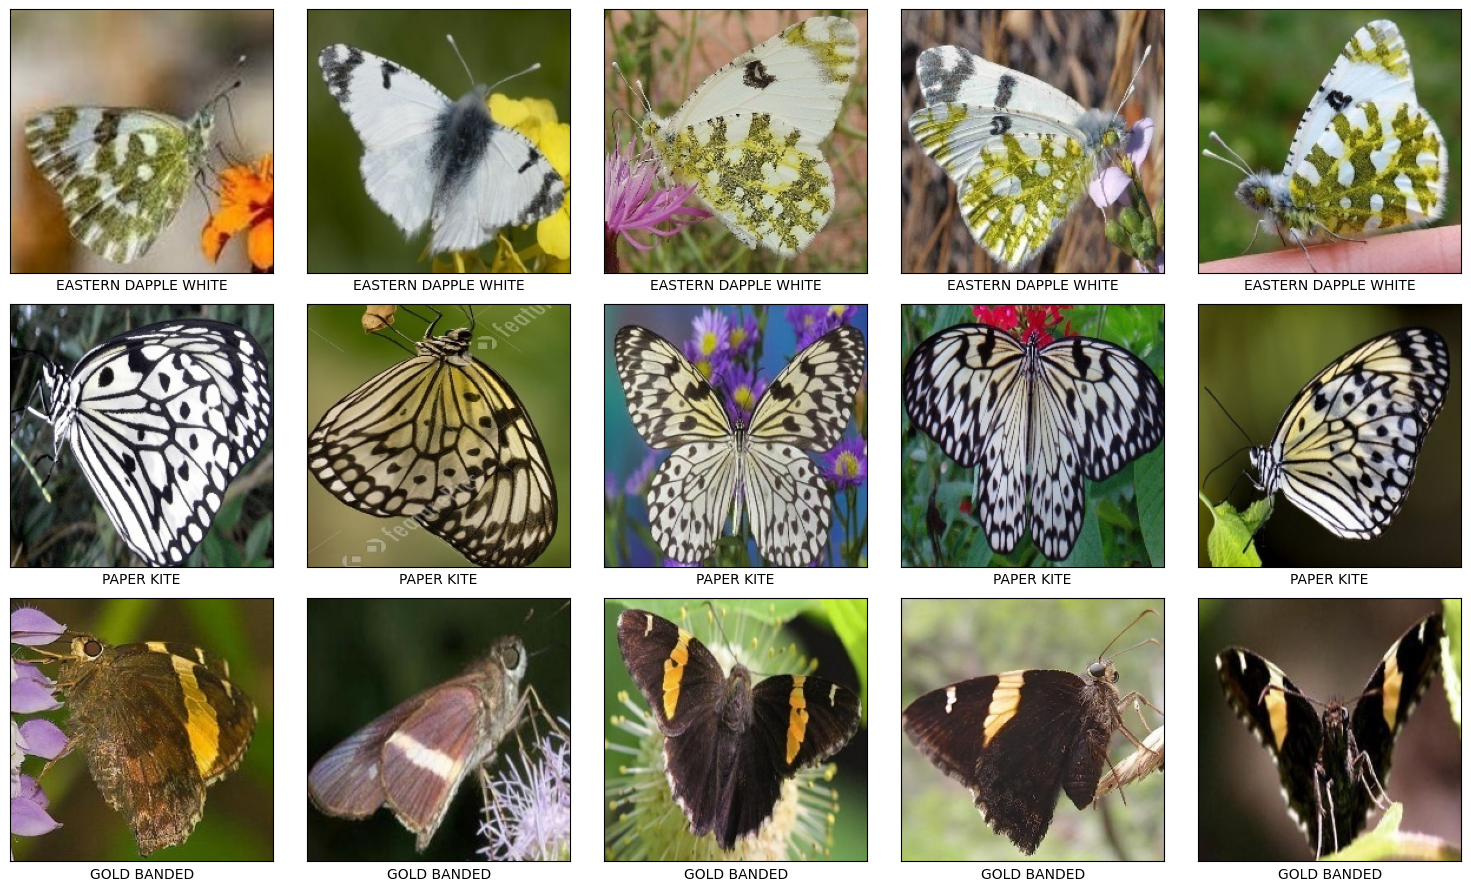

In [14]:
selected_classes = random.sample(list(butterfly_images.keys()), 3)

# Membuat grid visualisasi: 3 baris (kelas) x 5 kolom (sampel gambar)
fig, axs = plt.subplots(len(selected_classes), 5, figsize=(15, 9))

for i, class_name in enumerate(selected_classes):
    # Mengambil 5 gambar acak dari kelas tersebut
    # Petunjuk: Pilih array daftar gambar dari kelas yang sedang aktif di kamus
    sample_images = np.random.choice(butterfly_images[class_name], 5, replace=False)

    for j, image_name in enumerate(sample_images):
        img_path = os.path.join(combined_dir, class_name, image_name)

        # Buka gambar menggunakan PIL Image
        img = Image.open(img_path)

        # Petunjuk:
        # Jika ingin tetap berwarna (RGB), gunakan .convert("RGB")
        # Jika ingin grayscale, gunakan .convert("L")
        img = img.convert("RGB")

        axs[i, j].imshow(img)
        axs[i, j].set(xlabel=class_name, xticks=[], yticks=[])

fig.tight_layout()
plt.show()

In [15]:
file_name = []
labels = []
full_path = []

# 2. Menelusuri seluruh direktori dan mengumpulkan data
for path, subdirs, files in os.walk(combined_dir):
    for name in files:
        full_path.append(os.path.join(path, name))
        # Mengambil nama folder sebagai label
        # (path.split('/')[-1] mengambil elemen terakhir dari path folder)
        labels.append(path.split('/')[-1])
        file_name.append(name)

                                         path       file_name     labels
0  butterfly/dataset/METALMARK/Image_6307.jpg  Image_6307.jpg  METALMARK
1   butterfly/dataset/METALMARK/Image_501.jpg   Image_501.jpg  METALMARK
2   butterfly/dataset/METALMARK/Image_300.jpg   Image_300.jpg  METALMARK
3  butterfly/dataset/METALMARK/Image_1664.jpg  Image_1664.jpg  METALMARK
4  butterfly/dataset/METALMARK/Image_5767.jpg  Image_5767.jpg  METALMARK

Statistik jumlah gambar per kelas:
count     75.000000
mean      86.653333
std        9.267049
min       71.000000
25%       81.000000
50%       86.000000
75%       92.000000
max      131.000000
Name: count, dtype: float64




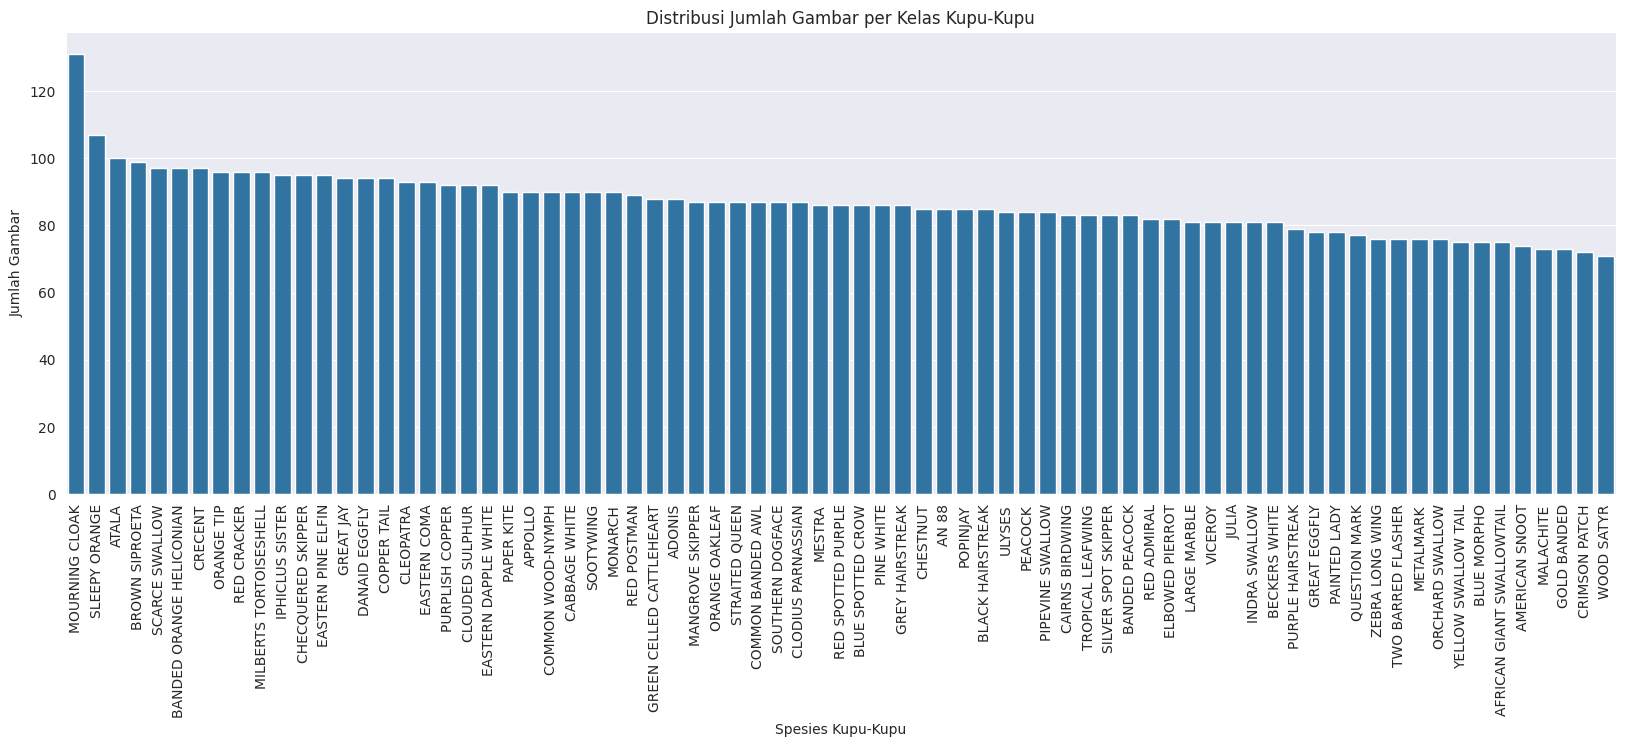

In [16]:
distribution_train = pd.DataFrame({"path": full_path, "file_name": file_name, "labels": labels})

# Menampilkan 5 baris pertama DataFrame
print(distribution_train.head())

# 4. Memeriksa ringkasan statistik jumlah gambar per kelas
print("\nStatistik jumlah gambar per kelas:")
print(distribution_train['labels'].value_counts().describe())
print("\n")

# 5. Plot distribusi gambar menggunakan Seaborn
plt.figure(figsize=(20, 6)) # Ukuran diperlebar agar 75 kelas muat
sns.set_style("darkgrid")

# Petunjuk: Isi data yang ingin dihitung frekuensinya (kolom label)
sns.countplot(data=distribution_train, x='labels', order=distribution_train['labels'].value_counts().index)

# Memutar teks sumbu X sebesar 90 derajat agar terbaca vertikal
plt.xticks(rotation=90)
plt.title("Distribusi Jumlah Gambar per Kelas Kupu-Kupu")
plt.xlabel("Spesies Kupu-Kupu")
plt.ylabel("Jumlah Gambar")
plt.show()

In [17]:
df = pd.DataFrame({"path":full_path,'file_name':file_name,"labels":labels})
# Melihat jumlah data gambar pada masing-masing label
df.groupby(['labels']).size()

,0
labels,
ADONIS,88
AFRICAN GIANT SWALLOWTAIL,75
AMERICAN SNOOT,74
AN 88,85
APPOLLO,90
...,...
ULYSES,84
VICEROY,81
WOOD SATYR,71


In [18]:
# 2. Pemisahan Data (Two-step train_test_split)
X = df['path']
y = df['labels']

# Split 1: Pisahkan 80% Train dan 20% Sisa (Val + Test)
# Petunjuk: Tentukan test_size untuk menyisakan 20% data
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.2, random_state=300, stratify=y
)

# Split 2: Bagi data sisa 20% menjadi dua sama rata (10% Val dan 10% Test)
# Petunjuk: Agar 20% terbagi rata (masing-masing 10%), berapa test_size dari data sisa tersebut? (50% = 0.5)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=300, stratify=y_temp
)

In [19]:
# 3. Menyatukan ke dalam DataFrame masing-masing
df_tr = pd.DataFrame({'path': X_train, 'labels': y_train, 'set': 'train'})
df_val = pd.DataFrame({'path': X_val, 'labels': y_val, 'set': 'val'})
df_te = pd.DataFrame({'path': X_test, 'labels': y_test, 'set': 'test'})

In [20]:
# Gabungkan ketiga dataframe
# Petunjuk: Masukkan df_tr, df_val, dan df_te ke dalam list pd.concat
df_all = pd.concat([df_tr, df_val, df_te], ignore_index=True)

print('===================================================== \n')
print(df_all.groupby(['set', 'labels']).size(), '\n')
print('===================================================== \n')

# Cek sampel data
print(df_all.sample(5))

# Membuat variabel Dataset, tempat menampung data yang telah dilakukan pembagian data training dan testing
target_split_dir = "dataset_final"


set   labels                   
test  ADONIS                       9
      AFRICAN GIANT SWALLOWTAIL    8
      AMERICAN SNOOT               7
      AN 88                        9
      APPOLLO                      9
                                  ..
val   ULYSES                       8
      VICEROY                      8
      WOOD SATYR                   7
      YELLOW SWALLOW TAIL          7
      ZEBRA LONG WING              7
Length: 225, dtype: int64 


                                                   path               labels  \
774           butterfly/dataset/METALMARK/Image_539.jpg            METALMARK   
3546  butterfly/dataset/YELLOW SWALLOW TAIL/Image_92...  YELLOW SWALLOW TAIL   
5151        butterfly/dataset/BLUE MORPHO/Image_663.jpg          BLUE MORPHO   
5147      butterfly/dataset/GREAT EGGFLY/Image_4471.jpg         GREAT EGGFLY   
1905      butterfly/dataset/EASTERN COMA/Image_3021.jpg         EASTERN COMA   

        set  
774   train  
3546  train  
5151  tr

In [21]:
print("\nMemindahkan gambar ke struktur folder train/val/test...")
for index, row in tq(df_all.iterrows(), total=len(df_all)):
    file_path = row['path']
    set_name = row['set']
    label_name = row['labels']

    # Buat direktori tujuan: dataset_final/<set>/<label>
    dest_dir = os.path.join(target_split_dir, set_name, label_name)
    os.makedirs(dest_dir, exist_ok=True)

    # Ambil nama file asli dari path
    destination_file_name = os.path.basename(file_path)

    # Salin file ke folder tujuan dengan nama aslinya
    dest_file = os.path.join(dest_dir, destination_file_name)
    if not os.path.exists(dest_file):
        shutil.copy2(file_path, dest_file)

print("\nData Splitting 3-bagian selesai dengan sukses!")


Memindahkan gambar ke struktur folder train/val/test...


  0%|          | 0/6499 [00:00<?, ?it/s]


Data Splitting 3-bagian selesai dengan sukses!


In [22]:
# Menentukan path direktori data train, val, dan test
TRAIN_DIR = "dataset_final/train"
VAL_DIR   = "dataset_final/val"
TEST_DIR  = "dataset_final/test"

# Menghitung total gambar di masing-masing direktori (75 kelas)
total_train = sum([len(os.listdir(os.path.join(TRAIN_DIR, c))) for c in os.listdir(TRAIN_DIR)])
total_val   = sum([len(os.listdir(os.path.join(VAL_DIR, c))) for c in os.listdir(VAL_DIR)])
total_test  = sum([len(os.listdir(os.path.join(TEST_DIR, c))) for c in os.listdir(TEST_DIR)])

print("Total images in training set   : ", total_train)
print("Total images in validation set : ", total_val)
print("Total images in test set       : ", total_test)

Total images in training set   :  5199
Total images in validation set :  650
Total images in test set       :  650


```markdown
### Offline Data Augmentation (Minority Classes)
Melakukan augmentasi secara offline khusus untuk kelas yang memiliki nilai F1-Score yang rendah (GREAT EGGFLY, CLEOPATRA, AMERICAN SNOOT, CLOUDED SULPHUR) pada set training agar model lebih robust.
```

In [23]:
import os
from tqdm.notebook import tqdm
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array, save_img

# Direktori training (pastikan hanya mengaugmentasi data latih)
train_dir = "dataset_final/train"

# Kelas target yang membutuhkan augmentasi ekstra
target_classes = ['GREAT EGGFLY', 'CLEOPATRA', 'AMERICAN SNOOT', 'CLOUDED SULPHUR']

# Mendefinisikan parameter augmentasi
datagen = ImageDataGenerator(
    rotation_range=30,
    zoom_range=0.2,
    width_shift_range=0.2,
    height_shift_range=0.2,
    horizontal_flip=True,
    brightness_range=[0.8, 1.2],   # Manipulasi kecerahan
    channel_shift_range=20.0,      # Color jitter (pergeseran nilai warna/channel)
    fill_mode='nearest'
)

print("Memulai Offline Augmentation...")

for cls in target_classes:
    class_dir = os.path.join(train_dir, cls)

    if not os.path.exists(class_dir):
        print(f"Peringatan: Direktori {class_dir} tidak ditemukan. Melewati...")
        continue

    # Membaca seluruh file gambar asli (mengabaikan file yang sudah diaugmentasi sebelumnya)
    image_files = [f for f in os.listdir(class_dir)
                   if f.lower().endswith(('.png', '.jpg', '.jpeg')) and not f.startswith('aug_')]

    print(f"\nMemproses kelas: {cls} ({len(image_files)} gambar asli)")

    # Iterasi pada setiap gambar menggunakan tqdm
    for img_name in tqdm(image_files, desc=f"Augmentasi {cls}"):
        img_path = os.path.join(class_dir, img_name)

        # Load dan konversi gambar ke array numpy
        img = load_img(img_path)
        x = img_to_array(img)
        x = x.reshape((1,) + x.shape) # Ubah bentuk ke (1, height, width, channels)

        # Menghasilkan 3 gambar augmentasi per gambar asli
        i = 0
        for batch in datagen.flow(x, batch_size=1):
            aug_img = batch[0]

            # Penamaan file hasil augmentasi
            aug_name = f"aug_{i}_{img_name}"
            aug_path = os.path.join(class_dir, aug_name)

            # Simpan kembali ke folder yang sama
            save_img(aug_path, aug_img)

            i += 1
            if i >= 3: # Hentikan loop setelah 3 gambar augmentasi dibuat
                break

print("\nSelesai melakukan Offline Augmentation!")

Memulai Offline Augmentation...

Memproses kelas: GREAT EGGFLY (62 gambar asli)


Augmentasi GREAT EGGFLY:   0%|          | 0/62 [00:00<?, ?it/s]


Memproses kelas: CLEOPATRA (74 gambar asli)


Augmentasi CLEOPATRA:   0%|          | 0/74 [00:00<?, ?it/s]


Memproses kelas: AMERICAN SNOOT (59 gambar asli)


Augmentasi AMERICAN SNOOT:   0%|          | 0/59 [00:00<?, ?it/s]


Memproses kelas: CLOUDED SULPHUR (74 gambar asli)


Augmentasi CLOUDED SULPHUR:   0%|          | 0/74 [00:00<?, ?it/s]


Selesai melakukan Offline Augmentation!


### Menghapus Data Augmentasi Clouded Sulphur
Menghapus file aug_*.jpg di dalam folder CLOUDED SULPHUR karena model membutuhkan warna asli kupu-kupu tersebut tanpa distorsi color jitter.

In [24]:
import glob

clouded_sulphur_dir = os.path.join(train_dir, 'CLOUDED SULPHUR')
aug_files = glob.glob(os.path.join(clouded_sulphur_dir, 'aug_*.jpg')) + glob.glob(os.path.join(clouded_sulphur_dir, 'aug_*.png')) + glob.glob(os.path.join(clouded_sulphur_dir, 'aug_*.jpeg'))

print(f"Menemukan {len(aug_files)} file augmentasi di kelas CLOUDED SULPHUR.")
for f in aug_files:
    try:
        os.remove(f)
    except Exception as e:
        print(f"Gagal menghapus {f}: {e}")
print("Penghapusan data augmentasi CLOUDED SULPHUR selesai.")

Menemukan 222 file augmentasi di kelas CLOUDED SULPHUR.
Penghapusan data augmentasi CLOUDED SULPHUR selesai.


### Augmentasi Kelas yang Baru Jatuh
Menerapkan skrip offline augmentation pada 4 kelas baru yang sekarang berada di bawah F1-Score 80%.

In [25]:
new_target_classes = ['QUESTION MARK', 'LARGE MARBLE', 'SOUTHERN DOGFACE', 'ORCHARD SWALLOW']

print("Memulai Offline Augmentation untuk kelas baru...")

for cls in new_target_classes:
    class_dir = os.path.join(train_dir, cls)

    if not os.path.exists(class_dir):
        print(f"Peringatan: Direktori {class_dir} tidak ditemukan. Melewati...")
        continue

    image_files = [f for f in os.listdir(class_dir)
                   if f.lower().endswith(('.png', '.jpg', '.jpeg')) and not f.startswith('aug_')]

    print(f"\nMemproses kelas: {cls} ({len(image_files)} gambar asli)")

    for img_name in tqdm(image_files, desc=f"Augmentasi {cls}"):
        img_path = os.path.join(class_dir, img_name)

        img = load_img(img_path)
        x = img_to_array(img)
        x = x.reshape((1,) + x.shape)

        i = 0
        for batch in datagen.flow(x, batch_size=1):
            aug_img = batch[0]
            aug_name = f"aug_{i}_{img_name}"
            aug_path = os.path.join(class_dir, aug_name)
            save_img(aug_path, aug_img)

            i += 1
            if i >= 3:
                break

print("\nSelesai melakukan Offline Augmentation untuk kelas baru!")

Memulai Offline Augmentation untuk kelas baru...

Memproses kelas: QUESTION MARK (62 gambar asli)


Augmentasi QUESTION MARK:   0%|          | 0/62 [00:00<?, ?it/s]


Memproses kelas: LARGE MARBLE (65 gambar asli)


Augmentasi LARGE MARBLE:   0%|          | 0/65 [00:00<?, ?it/s]


Memproses kelas: SOUTHERN DOGFACE (70 gambar asli)


Augmentasi SOUTHERN DOGFACE:   0%|          | 0/70 [00:00<?, ?it/s]


Memproses kelas: ORCHARD SWALLOW (61 gambar asli)


Augmentasi ORCHARD SWALLOW:   0%|          | 0/61 [00:00<?, ?it/s]


Selesai melakukan Offline Augmentation untuk kelas baru!


In [26]:
# 2. Membuat Objek ImageDataGenerator
# Untuk Data Latih: Rescale + Augmentasi (mencegah overfitting)
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    shear_range=0.2,
    fill_mode='nearest'
)

# Untuk Data Validasi & Uji: HANYA RESCALE (evaluasi jujur tanpa manipulasi)
val_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

# 3. Menghubungkan Generator dengan Direktori Fisik
# Generator Data Latih
train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=(150, 150),
    batch_size=32,
    color_mode="rgb",       # Petunjuk: Pilih "rgb" atau "grayscale"
    class_mode="categorical",       # Petunjuk: Pilih "categorical" atau "binary"
    shuffle=True
)

# Generator Data Validasi
validation_generator = val_datagen.flow_from_directory(
    VAL_DIR,
    target_size=(150, 150),
    batch_size=32,
    color_mode="rgb",       # Petunjuk: Samakan dengan train_generator
    class_mode="categorical",       # Petunjuk: Samakan dengan train_generator
    shuffle=False
)

# Generator Data Uji (Test)
test_generator = test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=(150, 150),
    batch_size=1,            # 1 per 1 untuk pengujian mandiri
    color_mode="rgb",       # Petunjuk: Samakan dengan train_generator
    class_mode="categorical",       # Petunjuk: Samakan dengan train_generator
    shuffle=False
)


Found 6558 images belonging to 75 classes.
Found 650 images belonging to 75 classes.
Found 650 images belonging to 75 classes.


In [27]:
# Membersihkan sesi lama agar memori GPU/RAM segar
tf.keras.backend.clear_session()

# Inisialisasi Model Sequential
model = Sequential()

# Menentukan Input Layer secara eksplisit sesuai standar Keras terbaru
model.add(layers.Input(shape=(150, 150, 3)))

# Menambahkan Base Model ke dalam Sequential
model.add(base_model)

# Menambahkan Conv2D dan Pooling Layer milik kita sendiri (Syarat Kriteria 4)
# Petunjuk: Gunakan ukuran kernel (3, 3) pada Conv2D dan pool_size (2, 2) pada MaxPool2D
model.add(Conv2D(256, (3, 3), padding='same', activation='relu'))
model.add(BatchNormalization())
model.add(MaxPool2D((2, 2)))

# Perataan dan Fully Connected Layer
model.add(Flatten())
# Ditambahkan L2 regularization untuk mengontrol besaran bobot dan meredam overfitting
model.add(Dense(256, activation='relu', kernel_regularizer=l2(0.005)))
model.add(BatchNormalization())
# Ditingkatkan Dropout menjadi 0.5
model.add(Dropout(0.5))

# Output Layer untuk 75 Spesies Kupu-Kupu
# Petunjuk: Isi jumlah kelas dan fungsi aktivasi multikelas
model.add(Dense(75, activation='softmax'))

# Kompilasi Model
# Mengganti categorical_crossentropy dengan Focal Loss
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss=tf.keras.losses.CategoricalFocalCrossentropy(),
    metrics=['accuracy']
)

# Menampilkan Ringkasan Arsitektur Model
model.summary()


/tmp/ipykernel_1601/3512056803.py:5: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 5, 5, 256)      │     2,949,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 5, 5, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 2, 2, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       262,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 75)             │        19,275 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,491,083 (20.95 MB)

 Trainable params: 3,232,075 (12.33 MB)

 Non-trainable params: 2,259,008 (8.62 MB)

In [28]:
import time

# 1. Membuat Callback Kustom untuk Mencapai Target Submission (>= 85%)
class TargetCallback(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
      logs = logs or {}
      acc = logs.get('accuracy', 0)
      val_acc = logs.get('val_accuracy', 0)
      if acc >= 0.955 and val_acc >= 0.955:
          print(f"\n[INFO] Target >= 95% tercapai pada epoch {epoch+1}! (Train: {acc:.4f}, Val: {val_acc:.4f})")
          self.model.stop_training = True

# Callback tambahan: Menurunkan learning rate otomatis jika val_accuracy stagnan
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_accuracy',
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

# Callback EarlyStopping untuk menghentikan pelatihan dan menyimpan bobot terbaik
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_accuracy',
    patience=6,
    restore_best_weights=True,
    verbose=1
)

# 2. Menjalankan Pelatihan Model
print("Memulai pelatihan model CNN...")
start_time = time.time()

history_1 = model.fit(
    train_generator,
    epochs=40,
    validation_data=validation_generator,
    callbacks=[TargetCallback(), reduce_lr, early_stopping],
    verbose=1
)

end_time = time.time()
print(f"Pelatihan selesai dalam waktu: {(end_time - start_time)/60:.2f} menit")


Memulai pelatihan model CNN...
Epoch 1/40
205/205 ━━━━━━━━━━━━━━━━━━━━ 67s 252ms/step - accuracy: 0.2379 - loss: 2.7538 - val_accuracy: 0.4954 - val_loss: 2.2620 - learning_rate: 1.0000e-04
Epoch 2/40
205/205 ━━━━━━━━━━━━━━━━━━━━ 39s 189ms/step - accuracy: 0.4884 - loss: 2.2028 - val_accuracy: 0.6554 - val_loss: 1.9437 - learning_rate: 1.0000e-04
Epoch 3/40
205/205 ━━━━━━━━━━━━━━━━━━━━ 39s 189ms/step - accuracy: 0.6000 - loss: 1.9023 - val_accuracy: 0.7400 - val_loss: 1.7033 - learning_rate: 1.0000e-04
Epoch 4/40
205/205 ━━━━━━━━━━━━━━━━━━━━ 39s 189ms/step - accuracy: 0.6597 - loss: 1.6740 - val_accuracy: 0.7692 - val_loss: 1.5134 - learning_rate: 1.0000e-04
Epoch 5/40
205/205 ━━━━━━━━━━━━━━━━━━━━ 38s 187ms/step - accuracy: 0.6993 - loss: 1.4817 - val_accuracy: 0.7985 - val_loss: 1.3411 - learning_rate: 1.0000e-04
Epoch 6/40
205/205 ━━━━━━━━━━━━━━━━━━━━ 37s 180ms/step - accuracy: 0.7176 - loss: 1.3129 - val_accuracy: 0.7785 - val_loss: 1.2019 - learning_rate: 1.0000e-04
Epoch 7/40
205/

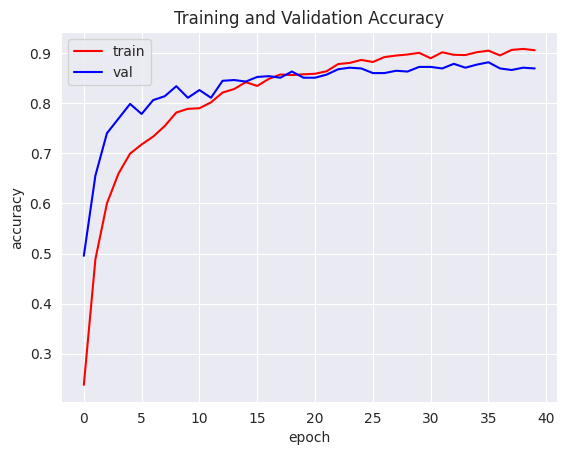

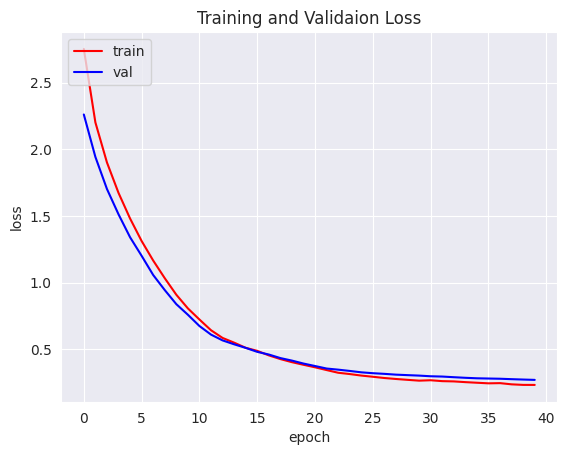

In [29]:
acc = history_1.history['accuracy']
val_acc = history_1.history['val_accuracy']
loss = history_1.history['loss']
val_loss = history_1.history['val_loss']

epochs = range(len(acc))

plt.plot(epochs, acc, 'r')
plt.plot(epochs, val_acc, 'b')
plt.title('Training and Validation Accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

print("\n")

plt.plot(epochs, loss, 'r')
plt.plot(epochs, val_loss, 'b')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.title('Training and Validaion Loss')
plt.show()

650/650 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step


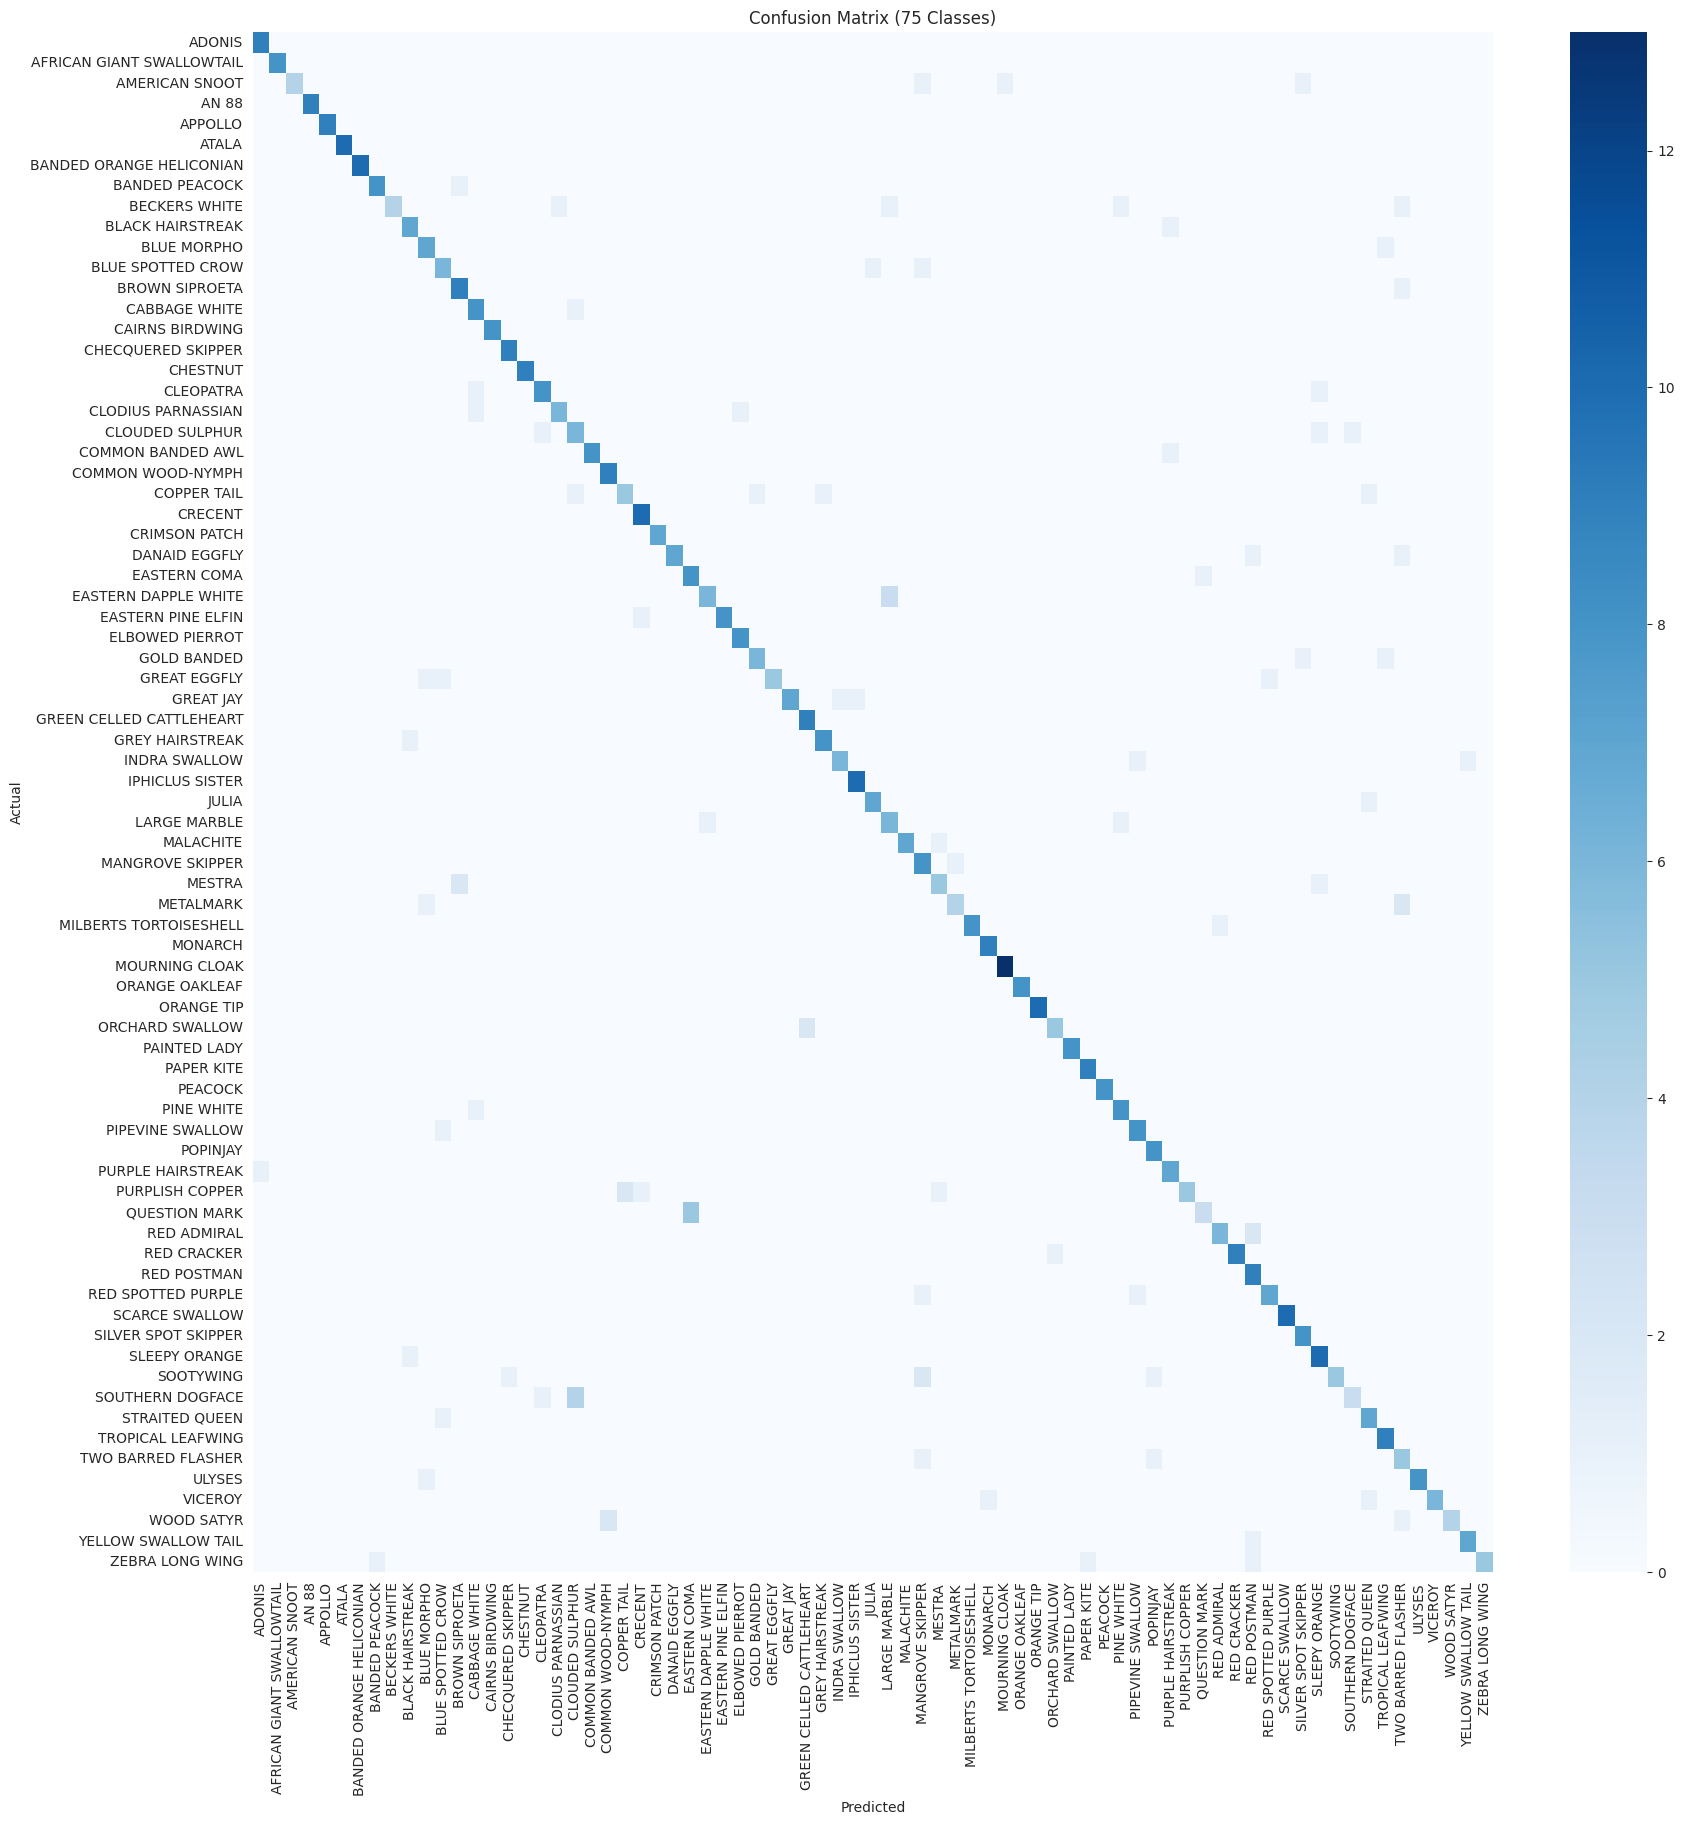


=== Classification Report ===

                           precision    recall  f1-score   support

                   ADONIS     0.9000    1.0000    0.9474         9
AFRICAN GIANT SWALLOWTAIL     1.0000    1.0000    1.0000         8
           AMERICAN SNOOT     1.0000    0.5714    0.7273         7
                    AN 88     1.0000    1.0000    1.0000         9
                  APPOLLO     1.0000    1.0000    1.0000         9
                    ATALA     1.0000    1.0000    1.0000        10
 BANDED ORANGE HELICONIAN     1.0000    1.0000    1.0000        10
           BANDED PEACOCK     0.8889    0.8889    0.8889         9
            BECKERS WHITE     1.0000    0.5000    0.6667         8
         BLACK HAIRSTREAK     0.7778    0.8750    0.8235         8
              BLUE MORPHO     0.7000    0.8750    0.7778         8
        BLUE SPOTTED CROW     0.6667    0.7500    0.7059         8
           BROWN SIPROETA     0.7500    0.9000    0.8182        10
            CABBAGE WHITE    

In [30]:
# 1. Reset generator untuk memastikan urutan data benar
test_generator.reset()

# 2. Lakukan prediksi pada seluruh data uji
raw_preds = model.predict(test_generator, verbose=1)

# 3. Ambil indeks kelas dengan probabilitas tertinggi untuk setiap sampel
y_pred = np.argmax(raw_preds, axis=1)
y_true = test_generator.classes

# 4. Mendapatkan daftar nama kelas asli secara berurutan
class_labels = list(test_generator.class_indices.keys())

# 5. Membuat dan Menampilkan Confusion Matrix
# Catatan: Karena ada 75 kelas, visualisasi heatmap akan sangat padat.
# Kita buat visualisasi berukuran besar agar tetap terbaca.
plt.figure(figsize=(20, 20))
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(
    cm,
    annot=False, # Dinonaktifkan karena angka akan menumpuk pada 75 kelas
    cmap="Blues",
    xticklabels=class_labels,
    yticklabels=class_labels
)
plt.title("Confusion Matrix (75 Classes)")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.show()

# 6. Menampilkan Classification Report Lengkap
print("\n=== Classification Report ===\n")
print(classification_report(y_true, y_pred, target_names=class_labels, digits=4))